# SENTINEL payments as a graph

This notebook loads a sample of SENTINEL transactions into Neo4j and runs three queries that are awkward to write over tables.

**Before running:** start Neo4j with `docker compose up -d` (browser on http://localhost:7474, user `neo4j`, password `sentinel123`).

## 1. Connect to Neo4j

In [1]:
import pandas as pd
import graph_loader as gl
import queries as q

pd.set_option("display.max_colwidth", 60)

driver = gl.connect()   # calls verify_connectivity()
print("Connected to", gl.NEO4J_URI)

Connected to bolt://localhost:7687


## 2. Read the sample

A continuous 14-day window of train transactions, joined with `fraud_label` from the labels table.
We take a time window instead of random rows so devices keep all the customers that used them.

In [2]:
tx = gl.read_sample()
print(f"{len(tx):,} transactions, {tx['fraud_label'].sum()} labelled fraud")
print("from", tx["transaction_time"].min(), "to", tx["transaction_time"].max())
tx.head()

31,937 transactions, 190 labelled fraud
from 2025-03-01 00:31:00.984000+00:00 to 2025-03-14 23:13:06.941000+00:00


,transaction_id,customer_id,merchant_id,device_id,transaction_amount,payment_channel,transaction_time,fraud_label
0,TX_0000238234,C_76f43ff2a66aaa89,M_ba1c04e407b82b9a,D_863b8629e59cf10f,3239.20,card,2025-03-01 00:31:00.984000+00:00,0
1,TX_0000238235,C_c207a8d037d9e144,M_28e395547b7866b3,D_530d96e41d17fae7,838.18,card,2025-03-01 00:31:27.048000+00:00,0
2,TX_0000238236,C_a1f6ed9a30131d98,M_5a27caae631583f4,D_4e53f1158555c317,699.42,UPI,2025-03-01 00:31:46.892000+00:00,0
3,TX_0000238237,C_76f43ff2a66aaa89,M_ba1c04e407b82b9a,D_863b8629e59cf10f,1951.08,card,2025-03-01 00:32:08.563000+00:00,0
4,TX_0000238238,C_c5ba75287449cf47,M_1152f966821333be,D_678903fcaa0ef758,1529.16,UPI,2025-03-01 00:32:24.021000+00:00,0


## 3. Constraints and load

Uniqueness constraints on `customer_id`, `device_id`, `merchant_id` (and `transaction_id` on PAID).
Every write is a `MERGE`, so running the load again does not create duplicates.

In [3]:
rows = gl.build_rows(tx)
gl.create_constraints(driver)
gl.load_graph(driver, rows)
gl.graph_counts(driver)

{'customers': 12376,
 'devices': 12810,
 'merchants': 1989,
 'used_device': 12987,
 'paid': 31937,
 'fraud_paid': 190}

Run the load a second time: the counts stay the same.

In [4]:
gl.load_graph(driver, rows)
gl.graph_counts(driver)

{'customers': 12376,
 'devices': 12810,
 'merchants': 1989,
 'used_device': 12987,
 'paid': 31937,
 'fraud_paid': 190}

## 4. Devices shared by 3+ customers within 7 days

Each `USED_DEVICE` edge stores the days the customer used that device. Every day is tried as a window start, and we keep the busiest 7-day window per device.

In [5]:
print(q.SHARED_DEVICES_7D)
shared = q.shared_devices_7d(driver)
print(len(shared), "devices")
shared.head(10)


MATCH (:Customer)-[u:USED_DEVICE]->(d:Device)
UNWIND u.days AS day
WITH d, collect(DISTINCT day) AS start_days
UNWIND start_days AS window_start
MATCH (c:Customer)-[u:USED_DEVICE]->(d)
WHERE any(day IN u.days WHERE window_start <= day < window_start + duration({days: 7}))
WITH d, window_start, collect(DISTINCT c.customer_id) AS customers
WHERE size(customers) >= $min_customers
ORDER BY size(customers) DESC, window_start
WITH d, collect({start: window_start, customers: customers})[0] AS busiest
RETURN d.device_id               AS device_id,
       d.kind                    AS device_kind,
       busiest.start             AS window_start,
       size(busiest.customers)   AS customers_in_7d,
       busiest.customers         AS customer_ids
ORDER BY customers_in_7d DESC, device_id



35 devices


,device_id,device_kind,window_start,customers_in_7d,customer_ids
0,D_116080aafcb8484e,mobile,2025-03-04,5,"[C_cce8bc936baed212, C_d7cc0d0af1b5457b, C_63ae67ddc4aff..."
1,D_81f27ef5f7ef0434,mobile,2025-03-02,5,"[C_e60aa596d8cd45d7, C_90f46bb3aae75255, C_7f7e49e2a4d01..."
2,D_adcb3d7a29cfc74d,browser,2025-03-02,5,"[C_8edd7135a6a6b930, C_63282e00999e30a5, C_655b087ec2e71..."
3,D_c1e439ced63f16cf,mobile,2025-03-04,5,"[C_be8dd73c37bbaf5e, C_b7289b7d80b98c60, C_8d841c256880c..."
4,D_425642355a48468b,mobile,2025-03-09,4,"[C_d66c7cb25dfe9e74, C_60a23ef368c5e450, C_31cdc247695ba..."
5,D_79e7e645f2648148,mobile,2025-03-09,4,"[C_f3ac049f9d6bd55f, C_e5f9ec1dd504901a, C_eb3c87900a4f0..."
6,D_8ddc1fb08b468259,browser,2025-03-02,4,"[C_cbf69c2217630bdc, C_eaaa408b27d6397b, C_a41f9f0e09860..."
7,D_d0e03094868c1f96,mobile,2025-03-05,4,"[C_f1e558e0d982a9cb, C_a8e7ae84bf4e8499, C_b8ce61e2d940f..."
8,D_ed87652853266454,mobile,2025-03-01,4,"[C_c207a8d037d9e144, C_1d9864cc1e361b0c, C_0198eb05e9d26..."
9,D_05c544848f1e6a6d,mobile,2025-03-01,3,"[C_aaec805f4fc50e20, C_763d15a3ef78d2ee, C_46d4ab50d5cc5..."


## 5. Customers within 2 hops of a fraud-labelled payment

From each customer with a fraud payment, walk two hops over `USED_DEVICE` or `PAID`. That reaches other customers through a shared device or a shared merchant. The device link is the stronger signal, so results are sorted by it.

In [6]:
print(q.NEAR_FRAUD_CUSTOMERS)
near = q.customers_near_fraud(driver)
print(len(near), "customers;", (near["shared_devices"] > 0).sum(), "linked through a shared device")
near.head(10)


MATCH (fraudster:Customer)-[:PAID {fraud_label: 1}]->(:Merchant)
WITH DISTINCT fraudster
MATCH (fraudster)-[:USED_DEVICE|PAID]-(link)-[:USED_DEVICE|PAID]-(c:Customer)
WHERE c <> fraudster
WITH c,
     collect(DISTINCT fraudster.customer_id)                            AS fraud_customers,
     collect(DISTINCT CASE WHEN link:Device THEN link.device_id END)     AS via_devices,
     collect(DISTINCT CASE WHEN link:Merchant THEN link.merchant_id END) AS via_merchants
OPTIONAL MATCH (c)-[own:PAID {fraud_label: 1}]->()
RETURN c.customer_id         AS customer_id,
       size(fraud_customers) AS linked_fraud_customers,
       size(via_devices)     AS shared_devices,
       size(via_merchants)   AS shared_merchants,
       count(own) > 0        AS has_own_fraud,
       via_devices
ORDER BY shared_devices DESC, linked_fraud_customers DESC, customer_id



2631 customers; 111 linked through a shared device


,customer_id,linked_fraud_customers,shared_devices,shared_merchants,has_own_fraud,via_devices
0,C_05201d2ea8541c26,5,1,2,False,[D_c1e439ced63f16cf]
1,C_689bdeac4499f7d7,5,1,1,False,[D_116080aafcb8484e]
2,C_8edd7135a6a6b930,5,1,1,False,[D_adcb3d7a29cfc74d]
3,C_400df65fd2c1001f,4,1,1,True,[D_7f9232cf27778c5a]
4,C_63282e00999e30a5,4,1,2,False,[D_adcb3d7a29cfc74d]
5,C_c7df63c12fd834fd,4,1,3,True,[D_adcb3d7a29cfc74d]
6,C_0961ff8fbbf39ea0,3,1,1,False,[D_1c294c146680d9b1]
7,C_1c5d37e5db48c436,3,1,2,False,[D_425642355a48468b]
8,C_24c9c7c78fc1a24e,3,1,1,False,[D_c22e153e34a4262b]
9,C_5c2627b6f558b7e7,3,1,0,False,[D_116080aafcb8484e]


Customers linked to fraud through a device, without fraud of their own, are good candidates for review:

In [7]:
near[(near["shared_devices"] > 0) & (~near["has_own_fraud"])].head(10)

,customer_id,linked_fraud_customers,shared_devices,shared_merchants,has_own_fraud,via_devices
0,C_05201d2ea8541c26,5,1,2,False,[D_c1e439ced63f16cf]
1,C_689bdeac4499f7d7,5,1,1,False,[D_116080aafcb8484e]
2,C_8edd7135a6a6b930,5,1,1,False,[D_adcb3d7a29cfc74d]
4,C_63282e00999e30a5,4,1,2,False,[D_adcb3d7a29cfc74d]
6,C_0961ff8fbbf39ea0,3,1,1,False,[D_1c294c146680d9b1]
7,C_1c5d37e5db48c436,3,1,2,False,[D_425642355a48468b]
8,C_24c9c7c78fc1a24e,3,1,1,False,[D_c22e153e34a4262b]
9,C_5c2627b6f558b7e7,3,1,0,False,[D_116080aafcb8484e]
10,C_655b087ec2e7176f,3,1,1,False,[D_adcb3d7a29cfc74d]
11,C_660e0e26bd6f93b3,3,1,1,False,[D_e37a0af139efb59a]


## 6. Merchants most often paid from shared devices

In [8]:
print(q.MERCHANTS_FROM_SHARED_DEVICES)
q.merchants_from_shared_devices(driver)


MATCH (c:Customer)-[:USED_DEVICE]->(d:Device)
WITH d, count(DISTINCT c) AS n_customers
WHERE n_customers >= $min_customers
WITH collect(d.device_id) AS shared_device_ids
MATCH (:Customer)-[p:PAID]->(m:Merchant)
WHERE p.device_id IN shared_device_ids
RETURN m.merchant_id                AS merchant_id,
       m.name                       AS merchant_name,
       m.category                   AS category,
       count(p)                     AS payments_from_shared,
       count(DISTINCT p.device_id)  AS shared_devices,
       sum(p.fraud_label)           AS fraud_payments,
       round(sum(p.amount), 2)      AS total_amount
ORDER BY payments_from_shared DESC
LIMIT $top_n



,merchant_id,merchant_name,category,payments_from_shared,shared_devices,fraud_payments,total_amount
0,M_fe6f6b20518185ea,Synthetic Merchant 001524,electronics,22,3,1,156995.64
1,M_daad973f17ef55ee,Synthetic Merchant 000764,electronics,22,3,0,72738.62
2,M_08b9601abb3c19c9,Synthetic Merchant 001465,gaming,19,3,1,64971.40
3,M_59e7277e69d97cae,Synthetic Merchant 001186,gift_cards,17,2,0,108935.04
4,M_fe7d206af92e0c16,Synthetic Merchant 001484,electronics,17,2,1,31055.60
5,M_8a78374d3977a8f1,Synthetic Merchant 000144,electronics,16,2,0,65406.41
6,M_ce21147943a8a773,Synthetic Merchant 000856,gift_cards,16,2,1,13857.88
7,M_3b03d0822001c40f,Synthetic Merchant 001424,electronics,16,2,2,182602.61
8,M_49595cb7144c965b,Synthetic Merchant 001815,gaming,16,2,1,20238.90
9,M_2a1a4fd0ec8c6a1e,Synthetic Merchant 000916,gift_cards,15,2,0,93230.49


Fraud rate on shared devices compared with all other payments:

In [9]:
q.run(driver, """
MATCH (c:Customer)-[:USED_DEVICE]->(d:Device)
WITH d, count(DISTINCT c) AS n_customers
WHERE n_customers >= 3
WITH collect(d.device_id) AS shared_device_ids
MATCH ()-[p:PAID]->()
WHERE p.device_id IS NOT NULL
WITH p, p.device_id IN shared_device_ids AS is_shared
RETURN is_shared, count(p) AS payments, sum(p.fraud_label) AS fraud,
       round(100.0 * sum(p.fraud_label) / count(p), 2) AS fraud_rate_pct
ORDER BY is_shared
""")

,is_shared,payments,fraud,fraud_rate_pct
0,False,30078,139,0.46
1,True,1304,45,3.45


In [10]:
driver.close()

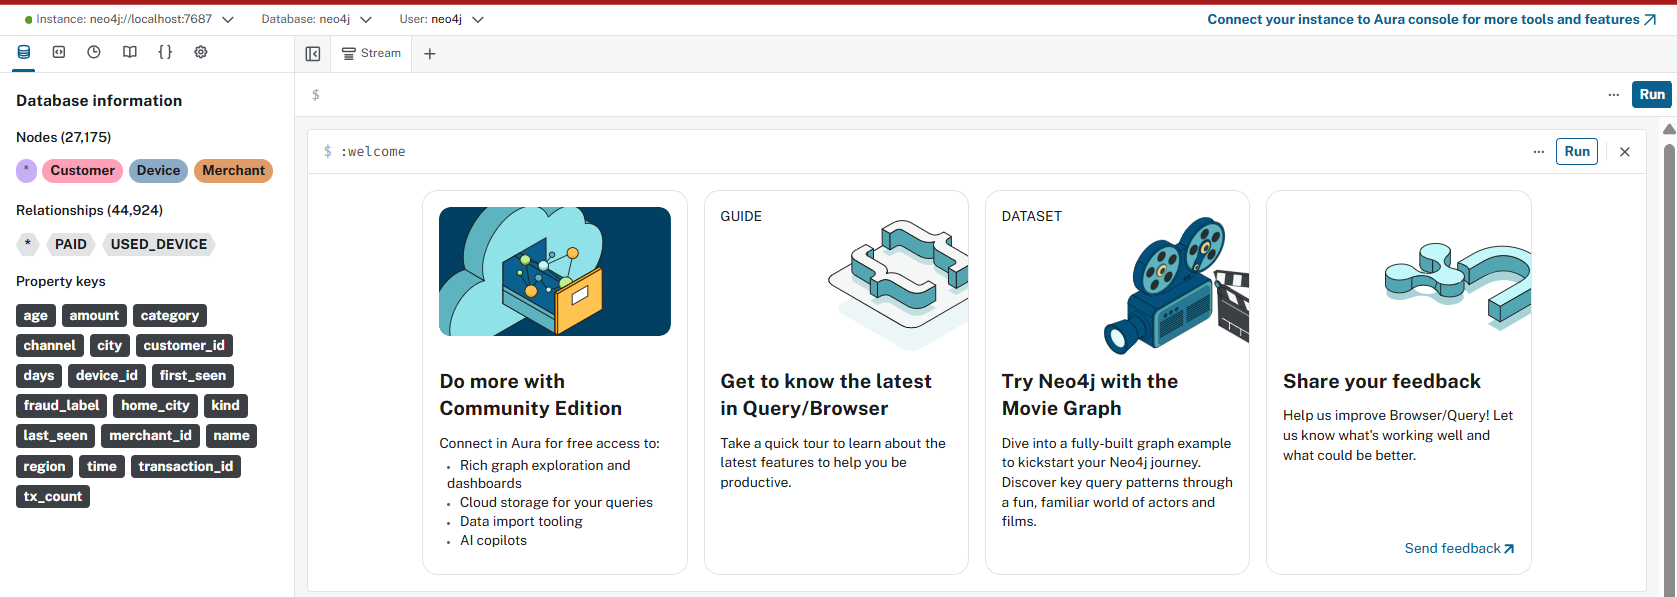

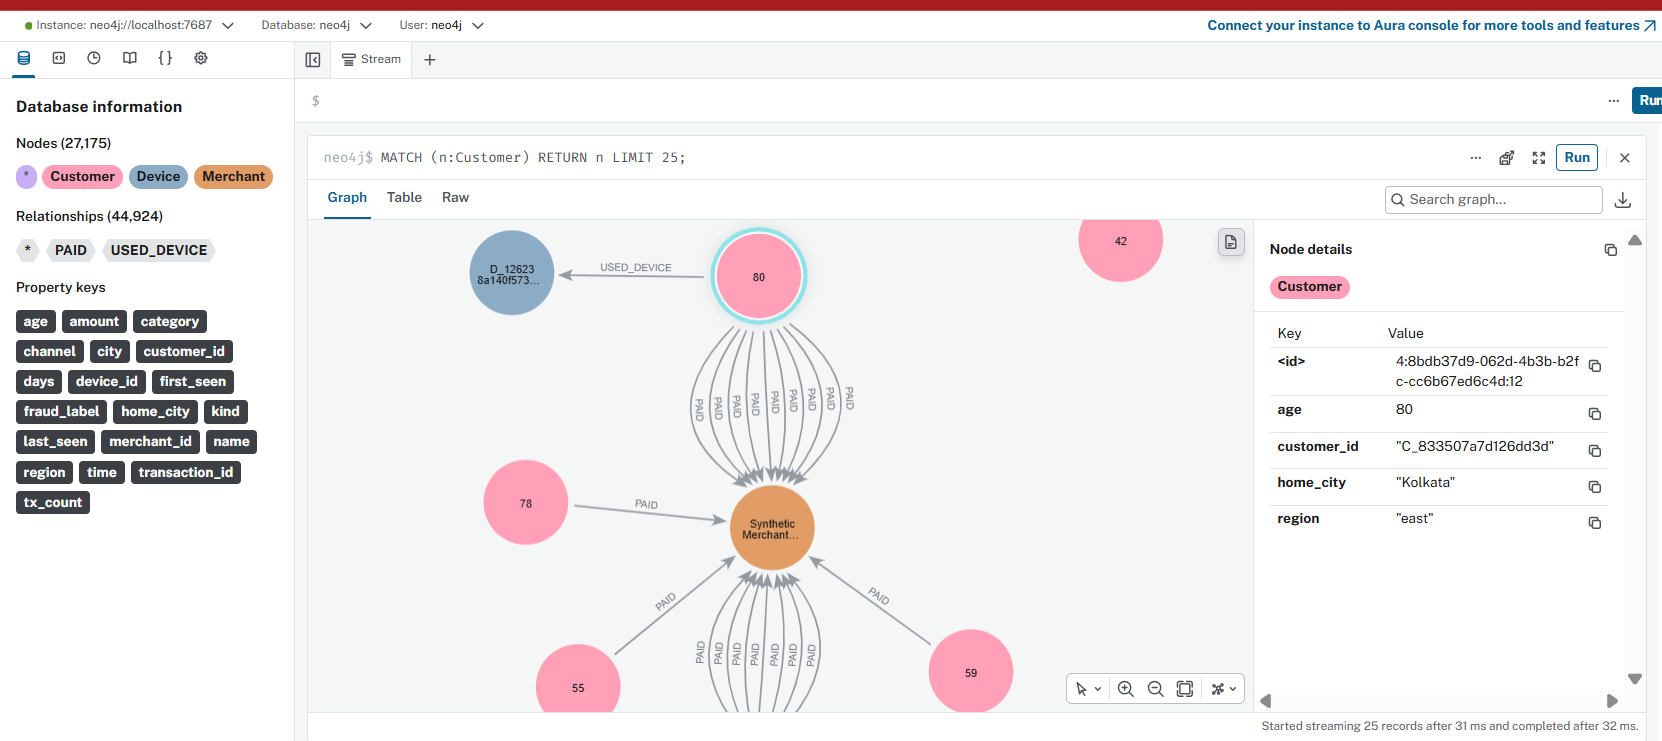
